In [1]:
import os
from datetime import date

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
spark = SparkSession.builder \
    .appName("AirQualityAnalysis") \
    .master("local[*]") \
    .config("spark.driver.memory", "6g") \
    .config("spark.sql.session.timeZone", "UTC") \
    .config("spark.sql.redaction.string.regex", "file:/\\S*/data") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

PROCESSED = "../data/processed"
FIGURES = "../figures"
POLLUTANTS = ["pm25", "pm10", "no2", "o3"]
COLORS = {"pm25": "#2a78d6", "pm10": "#eb6834", "no2": "#1baf7a", "o3": "#eda100"}
REGIONS = ["Paris", "Petite couronne", "Grande couronne", "Hors Ile-de-France"]
REGION_COLORS = {"Paris": "#1f3b73", "Petite couronne": "#5b8bd0", "Grande couronne": "#9a6fb0",
                 "Hors Ile-de-France": "#8a8a8a"}
SEASONS = ["winter", "spring", "summer", "autumn"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
WIND_CLASSES = ["calm", "moderate", "strong"]
TEMP_CLASSES = ["< 5", "5-15", "15-25", ">= 25"]
WELL_COVERED_YEARS = [2019, 2023, 2025]
MIN_COVERAGE = 0.75
DAILY_THRESHOLDS = {"pm10": 50, "pm25": 15, "no2": 25}
O3_HOURLY_THRESHOLD = 180
MIN_SITE_DAYS = 20
LOCKDOWN_START = date(2020, 3, 17)
LOCKDOWN_END = date(2020, 5, 11)

os.makedirs(FIGURES, exist_ok=True)
key_figures = []


def list_order(column, values):
    order = F.when(F.col(column) == values[0], 0)
    for i, v in enumerate(values[1:], 1):
        order = order.when(F.col(column) == v, i)
    return order

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/18 23:01:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Load the analysis tables

In [2]:
hourly = spark.read.parquet(PROCESSED + "/analysis_hourly")
daily = spark.read.parquet(PROCESSED + "/analysis_daily")
coverage = spark.read.parquet(PROCESSED + "/coverage")

hourly_years = hourly.filter(F.col("year").isin(WELL_COVERED_YEARS)).cache()
daily_years = daily.filter(F.col("year").isin(WELL_COVERED_YEARS)).cache()

print("analysis_hourly rows:", hourly.count())
print("analysis_daily rows:", daily.count())
print("coverage rows:", coverage.count())
print(f"Hourly rows in {WELL_COVERED_YEARS}:", hourly_years.count())
print(f"Daily rows in {WELL_COVERED_YEARS}:", daily_years.count())

hourly.createOrReplaceTempView("hourly")
hourly_years.createOrReplaceTempView("hourly_years")

analysis_hourly rows: 8508899
analysis_daily rows: 323126
coverage rows: 1542
Hourly rows in [2019, 2023, 2025]: 3377204
Daily rows in [2019, 2023, 2025]: 136355


## A. Location: mean concentration by region

In [3]:
region_means = spark.sql("""
    SELECT region, parameter, ROUND(AVG(value), 1) AS mean_value, COUNT(DISTINCT site_id) AS sites
    FROM hourly_years
    GROUP BY region, parameter
""")
region_means.groupBy("region").pivot("parameter", POLLUTANTS) \
    .agg(F.first("mean_value").alias("mean"), F.first("sites").alias("sites")) \
    .orderBy(list_order("region", REGIONS)).show(truncate=False)

means = {(r["region"], r["parameter"]): r["mean_value"] for r in region_means.collect()}
key_figures.append(("A Location", "Paris vs Hors Ile-de-France (µg/m³): " + ", ".join(
    f"{p} {means[('Paris', p)]} vs {means[('Hors Ile-de-France', p)]}" for p in POLLUTANTS)))

+------------------+---------+----------+---------+----------+--------+---------+-------+--------+
|region            |pm25_mean|pm25_sites|pm10_mean|pm10_sites|no2_mean|no2_sites|o3_mean|o3_sites|
+------------------+---------+----------+---------+----------+--------+---------+-------+--------+
|Paris             |11.6     |5         |23.0     |8         |31.7    |14       |49.3   |3       |
|Petite couronne   |10.7     |5         |20.4     |8         |27.5    |12       |48.6   |5       |
|Grande couronne   |8.9      |8         |15.7     |9         |19.5    |12       |55.2   |15      |
|Hors Ile-de-France|8.8      |21        |14.9     |29        |14.0    |28       |54.7   |23      |
+------------------+---------+----------+---------+----------+--------+---------+-------+--------+



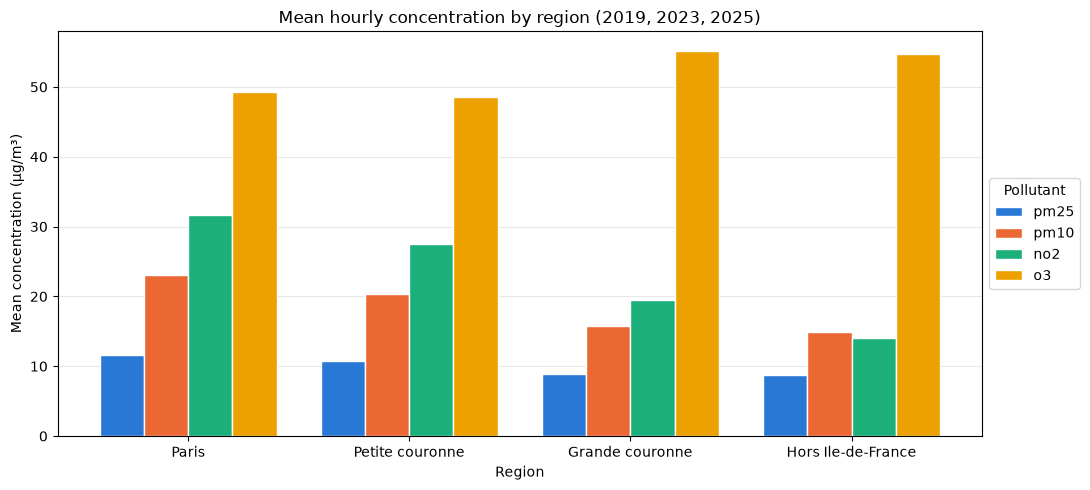

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
width = 0.2
for i, p in enumerate(POLLUTANTS):
    ax.bar([x + i * width for x in range(len(REGIONS))], [means.get((r, p), 0) for r in REGIONS],
           width, color=COLORS[p], edgecolor="white", label=p)
ax.set_xticks([x + 1.5 * width for x in range(len(REGIONS))])
ax.set_xticklabels(REGIONS)
ax.set_xlabel("Region")
ax.set_ylabel("Mean concentration (µg/m³)")
ax.set_title(f"Mean hourly concentration by region ({', '.join(str(y) for y in WELL_COVERED_YEARS)})")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(title="Pollutant", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(FIGURES + "/fig1_region.png", dpi=150, bbox_inches="tight")
plt.show()

## B. Daily, weekly and seasonal cycles

In [5]:
hourly_profile = hourly_years.groupBy("parameter", "is_weekend", "hour") \
    .agg(F.round(F.avg("value"), 1).alias("mean_value"))
hourly_profile.withColumn("serie", F.concat("parameter", F.lit("_"),
                                            F.when(F.col("is_weekend"), "weekend").otherwise("week"))) \
    .groupBy("hour").pivot("serie", [f"{p}_{d}" for p in POLLUTANTS for d in ["week", "weekend"]]) \
    .agg(F.first("mean_value")).orderBy("hour").show(24)

week_weekend = hourly_years.groupBy("parameter").agg(
    F.avg(F.when(~F.col("is_weekend"), F.col("value"))).alias("week"),
    F.avg(F.when(F.col("is_weekend"), F.col("value"))).alias("weekend")
).withColumn("weekend_change_pct", F.round((F.col("weekend") - F.col("week")) / F.col("week") * 100, 1)) \
    .select("parameter", F.round("week", 1).alias("week"), F.round("weekend", 1).alias("weekend"), "weekend_change_pct") \
    .orderBy(list_order("parameter", POLLUTANTS))
week_weekend.show()

monthly_profile = hourly_years.groupBy("parameter", "month").agg(F.round(F.avg("value"), 1).alias("mean_value"))
monthly_profile.groupBy("month").pivot("parameter", POLLUTANTS).agg(F.first("mean_value")).orderBy("month").show(12)

profile = {(r["parameter"], r["is_weekend"], r["hour"]): r["mean_value"] for r in hourly_profile.collect()}
month_means = {(r["parameter"], r["month"]): r["mean_value"] for r in monthly_profile.collect()}
weekend_change = {r["parameter"]: r["weekend_change_pct"] for r in week_weekend.collect()}
peak_hour = {p: max(range(24), key=lambda h: profile[(p, False, h)]) for p in POLLUTANTS}
peak_month = {p: max(range(1, 13), key=lambda m: month_means[(p, m)]) for p in POLLUTANTS}
print("Weekday peak hour:", ", ".join(f"{p} {peak_hour[p]}h" for p in POLLUTANTS))
print("Month with the highest mean:", ", ".join(f"{p} {MONTH_NAMES[peak_month[p] - 1]}" for p in POLLUTANTS))
key_figures.append(("B Cycles", "Weekday peak hour " + ", ".join(f"{p} {peak_hour[p]}h" for p in POLLUTANTS)
                    + "; weekend vs week " + ", ".join(f"{p} {weekend_change[p]:+}%" for p in POLLUTANTS)
                    + "; highest month " + ", ".join(f"{p} {MONTH_NAMES[peak_month[p] - 1]}" for p in POLLUTANTS)))

+----+---------+------------+---------+------------+--------+-----------+-------+----------+
|hour|pm25_week|pm25_weekend|pm10_week|pm10_weekend|no2_week|no2_weekend|o3_week|o3_weekend|
+----+---------+------------+---------+------------+--------+-----------+-------+----------+
|   0|      9.9|        10.8|     16.8|        17.5|    21.2|       23.8|   49.3|      49.1|
|   1|      9.6|        10.3|     16.1|        16.8|    18.7|       21.6|   47.7|      48.1|
|   2|      9.4|         9.8|     15.4|        15.8|    16.9|       18.7|   46.2|      47.3|
|   3|      9.2|         9.4|     14.9|        15.0|    15.7|       17.0|   45.2|      46.7|
|   4|      9.1|         9.3|     14.8|        14.5|    16.0|       15.5|   43.6|      45.6|
|   5|      9.1|         9.0|     15.1|        14.2|    18.6|       15.5|   41.3|      44.9|
|   6|      9.4|         9.1|     16.1|        14.3|    24.0|       16.5|   37.9|      43.3|
|   7|      9.8|         9.2|     17.6|        14.7|    29.7|       17

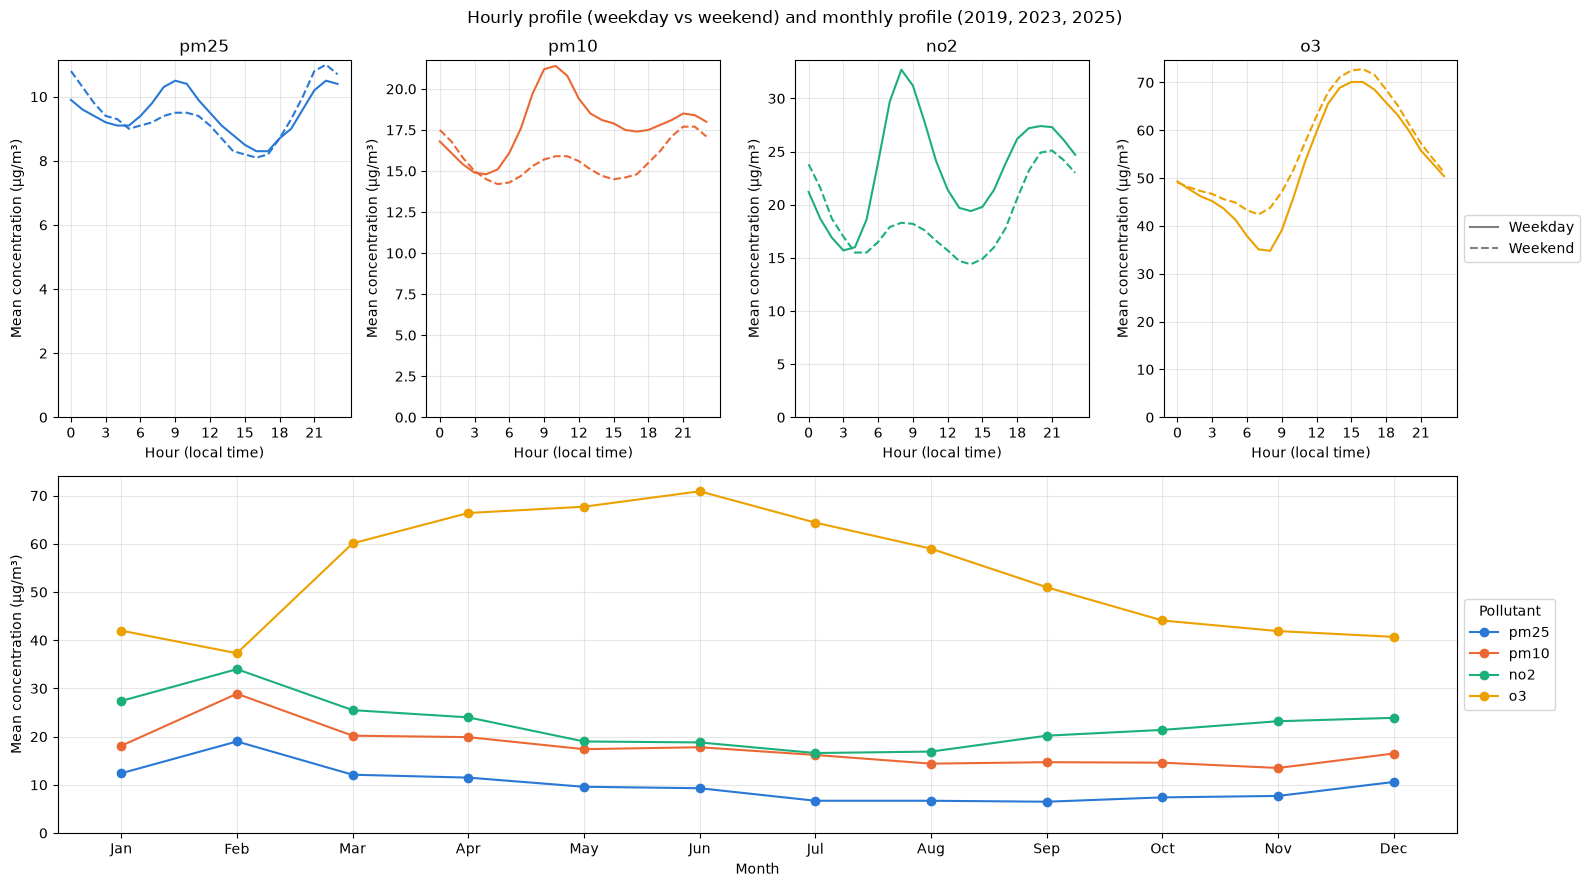

In [6]:
fig = plt.figure(figsize=(16, 9))
grid = fig.add_gridspec(2, 4)

for i, p in enumerate(POLLUTANTS):
    ax = fig.add_subplot(grid[0, i])
    ax.plot(range(24), [profile[(p, False, h)] for h in range(24)], color=COLORS[p], linewidth=1.5)
    ax.plot(range(24), [profile[(p, True, h)] for h in range(24)], color=COLORS[p], linewidth=1.5, linestyle="--")
    ax.set_title(p)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Hour (local time)")
    ax.set_ylabel("Mean concentration (µg/m³)")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="gray", linewidth=1.5, label="Weekday"),
                   Line2D([0], [0], color="gray", linewidth=1.5, linestyle="--", label="Weekend")],
          loc="center left", bbox_to_anchor=(1, 0.5))

ax = fig.add_subplot(grid[1, :])
for p in POLLUTANTS:
    ax.plot(range(1, 13), [month_means[(p, m)] for m in range(1, 13)], color=COLORS[p], linewidth=1.5,
            marker="o", markersize=6, label=p)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_NAMES)
ax.set_xlabel("Month")
ax.set_ylabel("Mean concentration (µg/m³)")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(title="Pollutant", loc="center left", bbox_to_anchor=(1, 0.5))

fig.suptitle(f"Hourly profile (weekday vs weekend) and monthly profile ({', '.join(str(y) for y in WELL_COVERED_YEARS)})")
plt.tight_layout()
plt.savefig(FIGURES + "/fig2_cycles.png", dpi=150, bbox_inches="tight")
plt.show()

## C. Comparison of the pollutants

In [7]:
daily_wide = daily_years.groupBy("site_id", "date").pivot("parameter", POLLUTANTS).agg(F.first("value")).cache()
print("Site-days:", daily_wide.count())
daily_wide.show(5)

correlations = []
for i, p1 in enumerate(POLLUTANTS):
    for p2 in POLLUTANTS[i + 1:]:
        result = daily_wide.filter(F.col(p1).isNotNull() & F.col(p2).isNotNull()) \
            .agg(F.corr(p1, p2).alias("r"), F.count("*").alias("days")).first()
        correlations.append((p1, p2, round(result["r"], 2), result["days"]))

spark.createDataFrame(correlations, ["pollutant_1", "pollutant_2", "pearson_r", "days"]).show()
key_figures.append(("C Pollutants", "Pearson r of daily means: " + ", ".join(
    f"{p1}-{p2} {r}" for p1, p2, r, days in correlations)))

Site-days: 65889
+-------+----------+----+-----+-----+-----+
|site_id|      date|pm25| pm10|  no2|   o3|
+-------+----------+----+-----+-----+-----+
|   4006|2019-01-29|NULL|11.53|16.35|35.89|
|   4034|2019-10-29|8.06|14.04|18.25| NULL|
|   4100|2019-11-28|NULL|  6.2| NULL|60.42|
|   4159|2025-05-25|4.94|11.83| 3.87| NULL|
|   2707|2019-05-21|NULL|18.71|12.65|53.79|
+-------+----------+----+-----+-----+-----+
only showing top 5 rows

+-----------+-----------+---------+-----+
|pollutant_1|pollutant_2|pearson_r| days|
+-----------+-----------+---------+-----+
|       pm25|       pm10|     0.83|16671|
|       pm25|        no2|     0.52|15141|
|       pm25|         o3|    -0.25|12299|
|       pm10|        no2|     0.67|21469|
|       pm10|         o3|    -0.13|15966|
|        no2|         o3|    -0.47|23011|
+-----------+-----------+---------+-----+



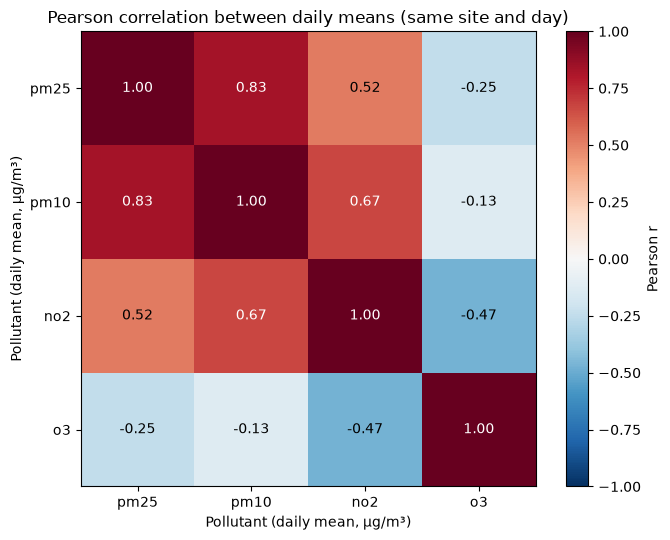

In [8]:
matrix = [[1.0 if p1 == p2 else 0.0 for p2 in POLLUTANTS] for p1 in POLLUTANTS]
for p1, p2, r, days in correlations:
    matrix[POLLUTANTS.index(p1)][POLLUTANTS.index(p2)] = r
    matrix[POLLUTANTS.index(p2)][POLLUTANTS.index(p1)] = r

fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(POLLUTANTS)):
    for j in range(len(POLLUTANTS)):
        ax.text(j, i, f"{matrix[i][j]:.2f}", ha="center", va="center",
                color="white" if abs(matrix[i][j]) > 0.6 else "black")
ax.set_xticks(range(len(POLLUTANTS)))
ax.set_xticklabels(POLLUTANTS)
ax.set_yticks(range(len(POLLUTANTS)))
ax.set_yticklabels(POLLUTANTS)
ax.set_xlabel("Pollutant (daily mean, µg/m³)")
ax.set_ylabel("Pollutant (daily mean, µg/m³)")
ax.set_title("Pearson correlation between daily means (same site and day)")
fig.colorbar(image, ax=ax, label="Pearson r")
plt.tight_layout()
plt.savefig(FIGURES + "/fig3_pollutants.png", dpi=150, bbox_inches="tight")
plt.show()

## D. Weather conditions

In [9]:
wind_means = hourly_years.groupBy("wind_class").pivot("parameter", POLLUTANTS) \
    .agg(F.round(F.avg("value"), 1)).orderBy(list_order("wind_class", WIND_CLASSES))
temp_means = hourly_years.groupBy("temp_class").pivot("parameter", POLLUTANTS) \
    .agg(F.round(F.avg("value"), 1)).orderBy(list_order("temp_class", TEMP_CLASSES))
rain_means = hourly_years.groupBy("rain").pivot("parameter", POLLUTANTS) \
    .agg(F.round(F.avg("value"), 1)).orderBy("rain")

wind_means.show()
temp_means.show()
rain_means.show()
wind_rows = wind_means.collect()
temp_rows = temp_means.collect()
rain_rows = rain_means.collect()

+----------+----+----+----+----+
|wind_class|pm25|pm10| no2|  o3|
+----------+----+----+----+----+
|      calm|11.8|20.6|29.3|44.0|
|  moderate|10.0|17.9|22.9|53.2|
|    strong| 6.1|12.8|14.4|62.2|
+----------+----+----+----+----+

+----------+----+----+----+-----+
|temp_class|pm25|pm10| no2|   o3|
+----------+----+----+----+-----+
|       < 5|16.8|22.8|31.6| 31.3|
|      5-15| 8.6|15.6|22.1| 50.5|
|     15-25| 7.8|16.5|18.3| 62.7|
|     >= 25| 9.2|22.2|21.0|100.7|
+----------+----+----+----+-----+

+-----+----+----+----+----+
| rain|pm25|pm10| no2|  o3|
+-----+----+----+----+----+
|false|10.1|18.3|23.0|53.8|
| true| 6.5|11.8|17.8|53.7|
+-----+----+----+----+----+



In [10]:
weather_corr = daily_years.groupBy("parameter").agg(
    F.round(F.corr("value", "temperature_mean"), 2).alias("r_temperature"),
    F.round(F.corr("value", "wind_speed_mean"), 2).alias("r_wind"),
    F.round(F.corr("value", "precipitation_total"), 2).alias("r_precipitation"),
    F.count("*").alias("days")
).orderBy(list_order("parameter", POLLUTANTS))
weather_corr.show()

r_weather = {r["parameter"]: r for r in weather_corr.collect()}
key_figures.append(("D Weather", f"no2 calm {wind_rows[0]['no2']} vs strong wind {wind_rows[2]['no2']}; "
                    f"o3 < 5 °C {temp_rows[0]['o3']} vs >= 25 °C {temp_rows[3]['o3']}; "
                    f"pm10 dry {rain_rows[0]['pm10']} vs rain {rain_rows[1]['pm10']} µg/m³; "
                    f"daily r: o3-temperature {r_weather['o3']['r_temperature']}, "
                    f"no2-wind {r_weather['no2']['r_wind']}, pm10-rain {r_weather['pm10']['r_precipitation']}"))

+---------+-------------+------+---------------+-----+
|parameter|r_temperature|r_wind|r_precipitation| days|
+---------+-------------+------+---------------+-----+
|     pm25|        -0.31| -0.32|          -0.21|20385|
|     pm10|        -0.08|  -0.3|          -0.24|30065|
|      no2|         -0.2| -0.31|           -0.1|50350|
|       o3|         0.51|  0.21|          -0.06|35555|
+---------+-------------+------+---------------+-----+



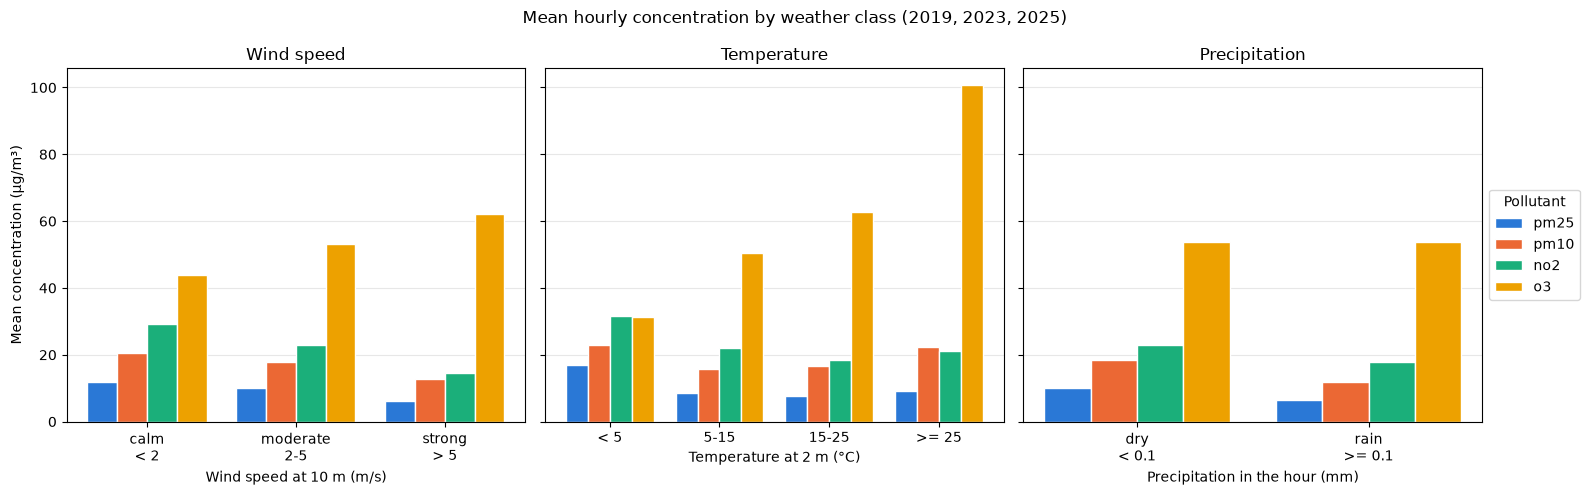

In [11]:
panels = [
    (wind_rows, ["calm\n< 2", "moderate\n2-5", "strong\n> 5"], "Wind speed", "Wind speed at 10 m (m/s)"),
    (temp_rows, ["< 5", "5-15", "15-25", ">= 25"], "Temperature", "Temperature at 2 m (°C)"),
    (rain_rows, ["dry\n< 0.1", "rain\n>= 0.1"], "Precipitation", "Precipitation in the hour (mm)")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
width = 0.2
for ax, (rows, labels, title, xlabel) in zip(axes, panels):
    for i, p in enumerate(POLLUTANTS):
        ax.bar([x + i * width for x in range(len(rows))], [r[p] for r in rows], width,
               color=COLORS[p], edgecolor="white", label=p)
    ax.set_xticks([x + 1.5 * width for x in range(len(rows))])
    ax.set_xticklabels(labels)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Mean concentration (µg/m³)")
axes[2].legend(title="Pollutant", loc="center left", bbox_to_anchor=(1, 0.5))
fig.suptitle(f"Mean hourly concentration by weather class ({', '.join(str(y) for y in WELL_COVERED_YEARS)})")
plt.tight_layout()
plt.savefig(FIGURES + "/fig4_weather.png", dpi=150, bbox_inches="tight")
plt.show()

## E. Trend and 2020 lockdown

In [12]:
well_covered = coverage.filter(F.col("year").isin(WELL_COVERED_YEARS) & (F.col("coverage") >= MIN_COVERAGE)) \
    .select("site_id", "parameter", "year")
print("Well covered (site, pollutant, year):", well_covered.count())
hourly_well = hourly.join(well_covered, ["site_id", "parameter", "year"], "left_semi")

trend = hourly_well.groupBy("parameter", "year").agg(
    F.round(F.avg("value"), 1).alias("mean_value"),
    F.countDistinct("site_id").alias("sites"))
trend.groupBy("parameter").pivot("year", WELL_COVERED_YEARS) \
    .agg(F.first("mean_value").alias("mean"), F.first("sites").alias("sites")) \
    .orderBy(list_order("parameter", POLLUTANTS)).show()

same_sites = well_covered.groupBy("site_id", "parameter").agg(F.countDistinct("year").alias("years")) \
    .filter(F.col("years") == len(WELL_COVERED_YEARS)).select("site_id", "parameter")
print("Check with the sites well covered in the three years:")
hourly_well.join(same_sites, ["site_id", "parameter"], "left_semi") \
    .groupBy("parameter").pivot("year", WELL_COVERED_YEARS) \
    .agg(F.round(F.avg("value"), 1).alias("mean"), F.countDistinct("site_id").alias("sites")) \
    .orderBy(list_order("parameter", POLLUTANTS)).show()

trend_means = {(r["parameter"], r["year"]): r["mean_value"] for r in trend.collect()}

Well covered (site, pollutant, year): 370
+---------+---------+----------+---------+----------+---------+----------+
|parameter|2019_mean|2019_sites|2023_mean|2023_sites|2025_mean|2025_sites|
+---------+---------+----------+---------+----------+---------+----------+
|     pm25|     10.4|        19|      8.8|        12|      9.6|        17|
|     pm10|     19.2|        37|     15.2|        17|     14.5|        18|
|      no2|     27.0|        56|     19.6|        44|     19.2|        51|
|       o3|     53.5|        40|     56.6|        33|     51.2|        26|
+---------+---------+----------+---------+----------+---------+----------+

Check with the sites well covered in the three years:
+---------+---------+----------+---------+----------+---------+----------+
|parameter|2019_mean|2019_sites|2023_mean|2023_sites|2025_mean|2025_sites|
+---------+---------+----------+---------+----------+---------+----------+
|     pm25|      9.8|         7|      8.5|         7|      9.6|         7|
|  

In [13]:
spark.sql("""
    SELECT h.site_id, h.region, h.parameter, h.year, h.value
    FROM hourly h
    JOIN (SELECT site_id, parameter
          FROM hourly
          WHERE year IN (2019, 2020) AND month BETWEEN 3 AND 5
          GROUP BY site_id, parameter
          HAVING COUNT(DISTINCT year) = 2) b
      ON h.site_id = b.site_id AND h.parameter = b.parameter
    WHERE h.year IN (2019, 2020) AND h.month BETWEEN 3 AND 5
""").createOrReplaceTempView("spring_both_years")

lockdown = spark.sql("""
    SELECT COALESCE(region, 'All regions') AS region, parameter,
           COUNT(DISTINCT site_id) AS sites,
           AVG(CASE WHEN year = 2019 THEN value END) AS mean_2019,
           AVG(CASE WHEN year = 2020 THEN value END) AS mean_2020
    FROM spring_both_years
    GROUP BY GROUPING SETS ((region, parameter), (parameter))
""").withColumn("change_pct", F.round((F.col("mean_2020") - F.col("mean_2019")) / F.col("mean_2019") * 100, 1)) \
    .withColumn("mean_2019", F.round("mean_2019", 1)) \
    .withColumn("mean_2020", F.round("mean_2020", 1))
lockdown.orderBy(list_order("parameter", POLLUTANTS), list_order("region", REGIONS + ["All regions"])) \
    .show(20, truncate=False)

lockdown_change = {(r["region"], r["parameter"]): r["change_pct"] for r in lockdown.collect()}
key_figures.append(("E Trend and lockdown", "Annual mean " + ", ".join(
    f"{p} {' -> '.join(str(trend_means[(p, y)]) for y in WELL_COVERED_YEARS)}" for p in POLLUTANTS)
    + "; spring 2020 vs 2019 " + ", ".join(f"{p} {lockdown_change[('All regions', p)]:+}%" for p in POLLUTANTS)))

+------------------+---------+-----+---------+---------+----------+
|region            |parameter|sites|mean_2019|mean_2020|change_pct|
+------------------+---------+-----+---------+---------+----------+
|Paris             |pm25     |1    |15.6     |13.8     |-11.2     |
|Petite couronne   |pm25     |4    |13.6     |12.5     |-8.3      |
|Grande couronne   |pm25     |6    |10.8     |10.1     |-6.1      |
|Hors Ile-de-France|pm25     |8    |12.2     |10.9     |-11.0     |
|All regions       |pm25     |19   |12.2     |11.1     |-9.5      |
|Paris             |pm10     |6    |28.6     |21.9     |-23.2     |
|Petite couronne   |pm10     |7    |24.7     |21.8     |-11.9     |
|Grande couronne   |pm10     |7    |18.3     |18.0     |-1.6      |
|Hors Ile-de-France|pm10     |20   |18.4     |17.7     |-3.8      |
|All regions       |pm10     |40   |21.1     |19.2     |-9.0      |
|Paris             |no2      |12   |42.8     |24.7     |-42.5     |
|Petite couronne   |no2      |12   |34.7     |23

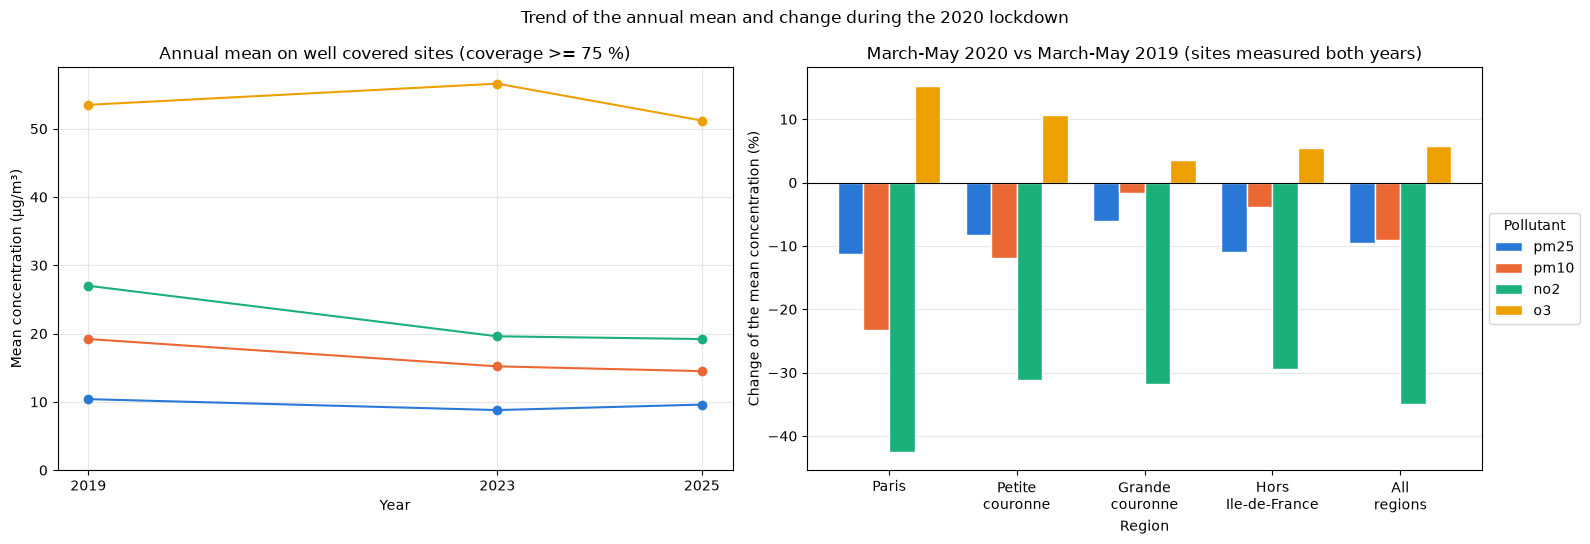

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

for p in POLLUTANTS:
    axes[0].plot(WELL_COVERED_YEARS, [trend_means[(p, y)] for y in WELL_COVERED_YEARS], color=COLORS[p],
                 linewidth=1.5, marker="o", markersize=6, label=p)
axes[0].set_xticks(WELL_COVERED_YEARS)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean concentration (µg/m³)")
axes[0].set_ylim(bottom=0)
axes[0].set_title("Annual mean on well covered sites (coverage >= 75 %)")
axes[0].grid(alpha=0.3)

groups = REGIONS + ["All regions"]
width = 0.2
for i, p in enumerate(POLLUTANTS):
    axes[1].bar([x + i * width for x in range(len(groups))], [lockdown_change.get((g, p), 0) for g in groups],
                width, color=COLORS[p], edgecolor="white", label=p)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xticks([x + 1.5 * width for x in range(len(groups))])
axes[1].set_xticklabels([g.replace(" ", "\n", 1) for g in groups])
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Change of the mean concentration (%)")
axes[1].set_title("March-May 2020 vs March-May 2019 (sites measured both years)")
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_axisbelow(True)
axes[1].legend(title="Pollutant", loc="center left", bbox_to_anchor=(1, 0.5))

fig.suptitle("Trend of the annual mean and change during the 2020 lockdown")
plt.tight_layout()
plt.savefig(FIGURES + "/fig5_trend_lockdown.png", dpi=150, bbox_inches="tight")
plt.show()

## F. Context for pollution episodes

In [15]:
thresholds = spark.createDataFrame(list(DAILY_THRESHOLDS.items()), ["parameter", "threshold"])
daily_days = daily_years.join(F.broadcast(thresholds), "parameter") \
    .select("site_id", "region", "parameter", "season", "date", "value", "threshold")
o3_days = hourly_years.filter(F.col("parameter") == "o3") \
    .withColumn("date", F.to_date("datetime_local")) \
    .groupBy("site_id", "region", "parameter", "season", "date") \
    .agg(F.max("value").alias("value")) \
    .withColumn("threshold", F.lit(O3_HOURLY_THRESHOLD))
daily_days.unionByName(o3_days).createOrReplaceTempView("episode_days")

episodes = spark.sql("""
    SELECT parameter, region,
           SUM(CASE WHEN value > threshold AND season = 'winter' THEN 1 ELSE 0 END) AS winter,
           SUM(CASE WHEN value > threshold AND season = 'spring' THEN 1 ELSE 0 END) AS spring,
           SUM(CASE WHEN value > threshold AND season = 'summer' THEN 1 ELSE 0 END) AS summer,
           SUM(CASE WHEN value > threshold AND season = 'autumn' THEN 1 ELSE 0 END) AS autumn,
           SUM(CASE WHEN value > threshold THEN 1 ELSE 0 END) AS days_above,
           COUNT(*) AS measured_days,
           ROUND(100 * AVG(CASE WHEN value > threshold THEN 1 ELSE 0 END), 1) AS pct_days_above
    FROM episode_days
    GROUP BY parameter, region
""")
episodes.orderBy(list_order("parameter", POLLUTANTS), list_order("region", REGIONS)).show(20, truncate=False)

overall = spark.sql("""
    SELECT parameter, MAX(threshold) AS threshold,
           SUM(CASE WHEN value > threshold THEN 1 ELSE 0 END) AS days_above,
           COUNT(*) AS measured_days,
           ROUND(100 * AVG(CASE WHEN value > threshold THEN 1 ELSE 0 END), 1) AS pct_days_above
    FROM episode_days
    GROUP BY parameter
""").orderBy(list_order("parameter", POLLUTANTS))
overall.show()

episode_rows = episodes.collect()
top_season = {p: max(SEASONS, key=lambda s: sum(r[s] for r in episode_rows if r["parameter"] == p)) for p in POLLUTANTS}
key_figures.append(("F Episodes", "Site-days above threshold: " + ", ".join(
    f"{r['parameter']} > {r['threshold']} {r['pct_days_above']}% (mostly {top_season[r['parameter']]})"
    for r in overall.collect())))

+---------+------------------+------+------+------+------+----------+-------------+--------------+
|parameter|region            |winter|spring|summer|autumn|days_above|measured_days|pct_days_above|
+---------+------------------+------+------+------+------+----------+-------------+--------------+
|pm25     |Paris             |126   |125   |99    |84    |434       |1849         |23.5          |
|pm25     |Petite couronne   |308   |226   |90    |79    |703       |3797         |18.5          |
|pm25     |Grande couronne   |333   |227   |52    |65    |677       |5500         |12.3          |
|pm25     |Hors Ile-de-France|642   |415   |79    |87    |1223      |9239         |13.2          |
|pm10     |Paris             |63    |35    |35    |15    |148       |4095         |3.6           |
|pm10     |Petite couronne   |92    |30    |18    |28    |168       |5501         |3.1           |
|pm10     |Grande couronne   |40    |5     |6     |0     |51        |5666         |0.9           |
|pm10     

## G. Region and weather conditions

In [16]:
conditions = [
    ("All conditions", "TRUE"),
    ("Calm wind", "wind_class = 'calm'"),
    ("Strong wind", "wind_class = 'strong'"),
    ("Dry", "NOT rain"),
    ("Rain", "rain"),
    ("< 5 °C", "temp_class = '< 5'"),
    (">= 25 °C", "temp_class = '>= 25'")
]
condition_names = [name for name, where in conditions]

region_weather = spark.sql(" UNION ALL ".join(f"""
    SELECT '{name}' AS condition, region, parameter, ROUND(AVG(value), 1) AS mean_value, COUNT(*) AS hours
    FROM hourly_years
    WHERE {where}
    GROUP BY region, parameter""" for name, where in conditions)).cache()

region_weather.groupBy("parameter", "condition").pivot("region", REGIONS).agg(F.first("mean_value")) \
    .orderBy(list_order("parameter", POLLUTANTS), list_order("condition", condition_names)).show(28, truncate=False)
print("Cells with the fewest hours:")
region_weather.orderBy("hours").show(5, truncate=False)

+---------+--------------+-----+---------------+---------------+------------------+
|parameter|condition     |Paris|Petite couronne|Grande couronne|Hors Ile-de-France|
+---------+--------------+-----+---------------+---------------+------------------+
|pm25     |All conditions|11.6 |10.7           |8.9            |8.8               |
|pm25     |Calm wind     |14.6 |14.0           |10.6           |10.8              |
|pm25     |Strong wind   |7.8  |6.6            |5.9            |5.8               |
|pm25     |Dry           |12.3 |11.5           |9.4            |9.5               |
|pm25     |Rain          |8.5  |7.2            |6.2            |6.0               |
|pm25     |< 5 °C        |18.8 |19.3           |15.9           |16.1              |
|pm25     |>= 25 °C      |12.4 |10.0           |8.5            |8.2               |
|pm10     |All conditions|23.0 |20.4           |15.7           |14.9              |
|pm10     |Calm wind     |27.4 |25.5           |18.4           |17.2        

In [17]:
paris = region_weather.filter(F.col("region") == "Paris") \
    .select("condition", "parameter", F.col("mean_value").alias("paris"))
outside = region_weather.filter(F.col("region") == "Hors Ile-de-France") \
    .select("condition", "parameter", F.col("mean_value").alias("outside"))
gap = paris.join(outside, ["condition", "parameter"]) \
    .withColumn("gap", F.round(F.col("paris") - F.col("outside"), 1)) \
    .withColumn("ratio", F.round(F.col("paris") / F.col("outside"), 2))

print("Paris - Hors Ile-de-France (gap in µg/m³, ratio Paris / Hors Ile-de-France):")
gap.groupBy("condition").pivot("parameter", POLLUTANTS) \
    .agg(F.first("gap").alias("gap"), F.first("ratio").alias("ratio")) \
    .orderBy(list_order("condition", condition_names)).show(truncate=False)

g_means = {(r["condition"], r["region"], r["parameter"]): r["mean_value"] for r in region_weather.collect()}
gaps = {(r["condition"], r["parameter"]): r["gap"] for r in gap.collect()}
key_figures.append(("G Region and weather", "Paris - Hors Ile-de-France no2 gap (µg/m³): " + ", ".join(
    f"{c} {gaps[(c, 'no2')]:+}" for c in condition_names)
    + f"; o3 gap all {gaps[('All conditions', 'o3')]:+}, >= 25 °C {gaps[('>= 25 °C', 'o3')]:+}"))

Paris - Hors Ile-de-France (gap in µg/m³, ratio Paris / Hors Ile-de-France):
+--------------+--------+----------+--------+----------+-------+---------+------+--------+
|condition     |pm25_gap|pm25_ratio|pm10_gap|pm10_ratio|no2_gap|no2_ratio|o3_gap|o3_ratio|
+--------------+--------+----------+--------+----------+-------+---------+------+--------+
|All conditions|2.8     |1.32      |8.1     |1.54      |17.7   |2.26     |-5.4  |0.9     |
|Calm wind     |3.8     |1.35      |10.2    |1.59      |23.0   |2.31     |-2.2  |0.95    |
|Strong wind   |2.0     |1.34      |6.5     |1.57      |13.7   |2.49     |-7.3  |0.88    |
|Dry           |2.8     |1.29      |8.5     |1.53      |18.1   |2.24     |-4.8  |0.91    |
|Rain          |2.5     |1.42      |5.7     |1.55      |15.2   |2.36     |-8.6  |0.85    |
|< 5 °C        |2.7     |1.17      |6.6     |1.32      |18.8   |1.85     |-8.9  |0.73    |
|>= 25 °C      |4.2     |1.51      |11.9    |1.64      |20.7   |2.68     |-2.1  |0.98    |
+------------

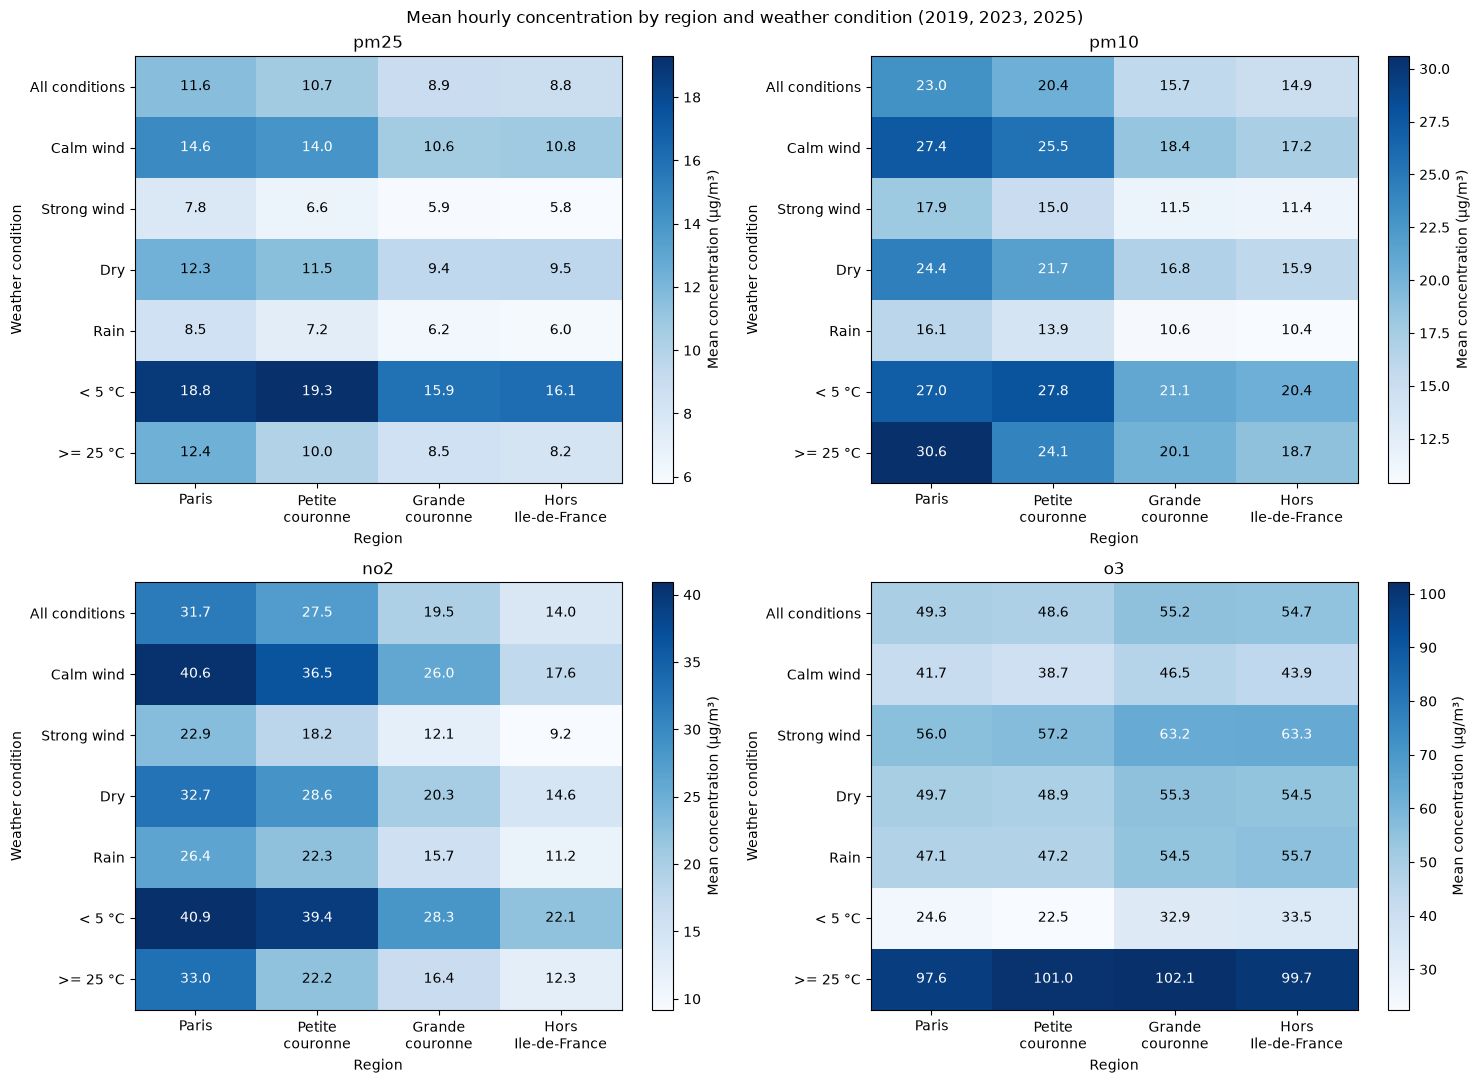

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, p in zip(axes.flatten(), POLLUTANTS):
    matrix = [[g_means.get((c, r, p), float("nan")) for r in REGIONS] for c in condition_names]
    low = min(v for row in matrix for v in row)
    high = max(v for row in matrix for v in row)
    image = ax.imshow(matrix, cmap="Blues", vmin=low, vmax=high, aspect="auto")
    for i in range(len(condition_names)):
        for j in range(len(REGIONS)):
            ax.text(j, i, f"{matrix[i][j]:.1f}", ha="center", va="center",
                    color="white" if matrix[i][j] > (low + high) / 2 else "black")
    ax.set_xticks(range(len(REGIONS)))
    ax.set_xticklabels([r.replace(" ", "\n", 1) for r in REGIONS])
    ax.set_yticks(range(len(condition_names)))
    ax.set_yticklabels(condition_names)
    ax.set_xlabel("Region")
    ax.set_ylabel("Weather condition")
    ax.set_title(p)
    fig.colorbar(image, ax=ax, label="Mean concentration (µg/m³)")
fig.suptitle(f"Mean hourly concentration by region and weather condition ({', '.join(str(y) for y in WELL_COVERED_YEARS)})")
plt.tight_layout()
plt.savefig(FIGURES + "/fig6_region_weather.png", dpi=150, bbox_inches="tight")
plt.show()

## H. All years by region

In [19]:
daily_period = daily.filter(F.col("date") < "2026-10-01")
months = spark.sql("SELECT explode(sequence(DATE'2018-01-01', DATE'2026-09-01', INTERVAL 1 MONTH)) AS month")
monthly = daily_period.withColumn("month", F.trunc("date", "month")) \
    .groupBy("region", "parameter", "month") \
    .agg(F.round(F.avg("value"), 1).alias("mean_value"), F.count("*").alias("site_days"))
monthly_full = months.crossJoin(daily_period.select("region", "parameter").distinct()) \
    .join(monthly, ["month", "region", "parameter"], "left") \
    .fillna(0, ["site_days"]) \
    .withColumn("plot_value", F.when(F.col("site_days") >= MIN_SITE_DAYS, F.col("mean_value"))) \
    .cache()

print("Months from January 2018 to September 2026:", months.count())
print(f"Months kept (at least {MIN_SITE_DAYS} valid site-days) and left empty:")
monthly_full.groupBy("parameter", "region").agg(
    F.sum(F.when(F.col("plot_value").isNotNull(), 1).otherwise(0)).alias("months_kept"),
    F.sum(F.when(F.col("plot_value").isNull(), 1).otherwise(0)).alias("months_empty"),
    F.round(F.avg("site_days"), 0).alias("mean_site_days")
).orderBy(list_order("parameter", POLLUTANTS), list_order("region", REGIONS)).show(16, truncate=False)

print("Example: no2 from January to June 2020")
monthly_full.filter((F.col("parameter") == "no2") & F.col("month").between("2020-01-01", "2020-06-01")) \
    .groupBy("month").pivot("region", REGIONS) \
    .agg(F.first("plot_value").alias("mean"), F.first("site_days").alias("site_days")) \
    .orderBy("month").show(truncate=False)

Months from January 2018 to September 2026: 105
Months kept (at least 20 valid site-days) and left empty:
+---------+------------------+-----------+------------+--------------+
|parameter|region            |months_kept|months_empty|mean_site_days|
+---------+------------------+-----------+------------+--------------+
|pm25     |Paris             |75         |30          |34.0          |
|pm25     |Petite couronne   |91         |14          |77.0          |
|pm25     |Grande couronne   |90         |15          |109.0         |
|pm25     |Hors Ile-de-France|97         |8           |199.0         |
|pm10     |Paris             |90         |15          |92.0          |
|pm10     |Petite couronne   |94         |11          |122.0         |
|pm10     |Grande couronne   |92         |13          |121.0         |
|pm10     |Hors Ile-de-France|99         |6           |340.0         |
|no2      |Paris             |98         |7           |260.0         |
|no2      |Petite couronne   |97         |

In [20]:
annual = daily_period.groupBy("region", "parameter", "year").agg(
    F.round(F.avg("value"), 1).alias("mean_value"),
    F.countDistinct("site_id").alias("sites"))
years = list(range(2018, 2027))

print("Annual mean of the valid days (µg/m³):")
annual.groupBy("parameter", "region").pivot("year", years).agg(F.first("mean_value")) \
    .orderBy(list_order("parameter", POLLUTANTS), list_order("region", REGIONS)).show(16, truncate=False)
print("Number of sites:")
annual.groupBy("parameter", "region").pivot("year", years).agg(F.first("sites")) \
    .orderBy(list_order("parameter", POLLUTANTS), list_order("region", REGIONS)).show(16, truncate=False)

annual_means = {(r["region"], r["parameter"], r["year"]): r["mean_value"] for r in annual.collect()}
empty_months = monthly_full.filter(F.col("plot_value").isNull()).count()
key_figures.append(("H All years", "no2 annual mean 2018 -> 2025: " + ", ".join(
    f"{r} {annual_means[(r, 'no2', 2018)]} -> {annual_means[(r, 'no2', 2025)]}" for r in REGIONS)
    + f"; {empty_months} of {monthly_full.count()} region-pollutant months left empty (< {MIN_SITE_DAYS} site-days)"))

Annual mean of the valid days (µg/m³):
+---------+------------------+----+----+----+----+----+----+----+----+----+
|parameter|region            |2018|2019|2020|2021|2022|2023|2024|2025|2026|
+---------+------------------+----+----+----+----+----+----+----+----+----+
|pm25     |Paris             |14.5|14.3|14.0|17.5|12.9|10.6|10.4|11.4|10.7|
|pm25     |Petite couronne   |13.0|11.9|11.9|11.9|11.7|9.5 |10.1|10.6|9.4 |
|pm25     |Grande couronne   |10.1|9.3 |8.4 |10.7|9.7 |8.4 |9.4 |8.3 |7.5 |
|pm25     |Hors Ile-de-France|9.6 |9.7 |8.7 |9.9 |10.0|8.1 |8.4 |8.8 |7.9 |
|pm10     |Paris             |26.5|25.1|22.2|22.8|21.2|21.6|19.2|19.7|19.6|
|pm10     |Petite couronne   |23.2|23.1|21.1|19.0|18.1|19.0|17.2|15.9|17.6|
|pm10     |Grande couronne   |18.6|17.8|16.3|16.3|15.9|14.9|14.6|13.5|14.1|
|pm10     |Hors Ile-de-France|16.4|16.0|14.5|15.6|14.4|13.8|13.2|13.9|14.2|
|no2      |Paris             |43.9|40.2|30.6|35.7|35.0|29.1|26.4|24.3|23.0|
|no2      |Petite couronne   |35.4|33.8|27.5|30.7

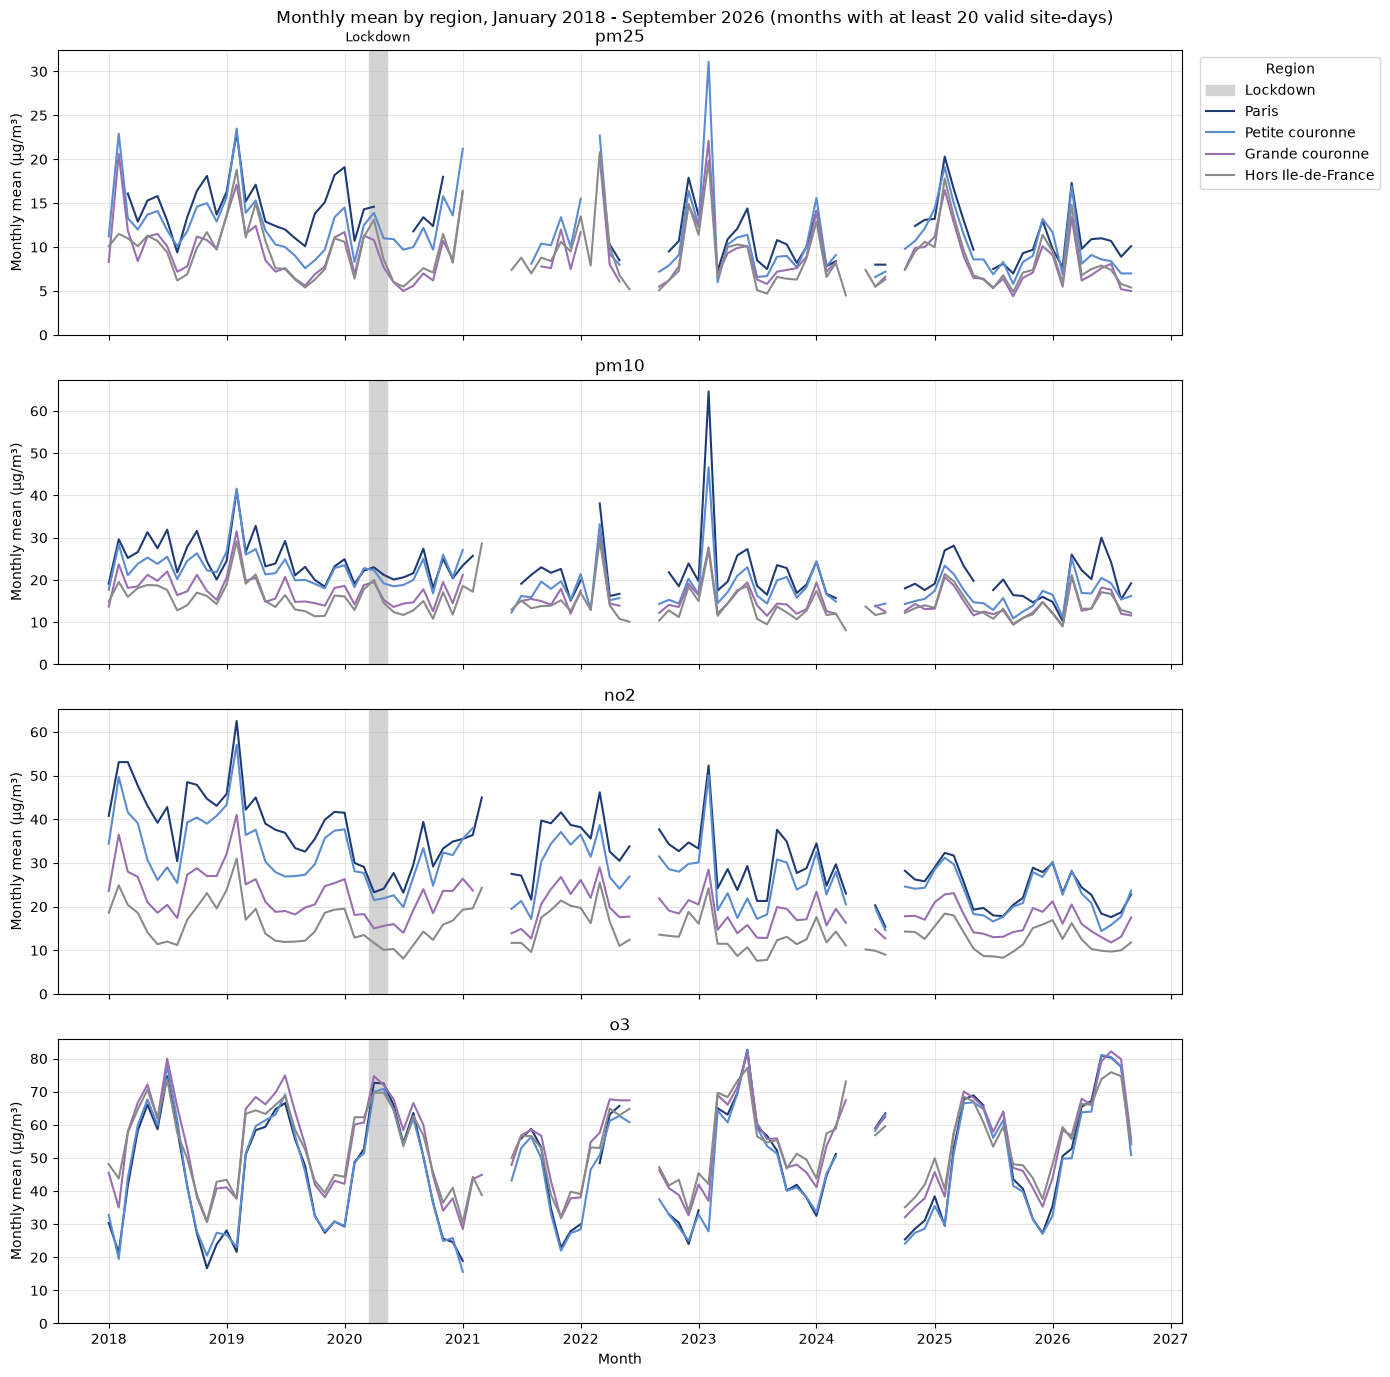

In [21]:
monthly_rows = monthly_full.collect()
month_list = sorted(set(r["month"] for r in monthly_rows))
monthly_values = {(r["region"], r["parameter"], r["month"]): r["plot_value"] for r in monthly_rows}

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
for ax, p in zip(axes, POLLUTANTS):
    ax.axvspan(LOCKDOWN_START, LOCKDOWN_END, color="lightgray", label="Lockdown")
    for r in REGIONS:
        values = [monthly_values.get((r, p, m)) for m in month_list]
        ax.plot(month_list, [float("nan") if v is None else v for v in values],
                color=REGION_COLORS[r], linewidth=1.5, label=r)
    ax.set_title(p)
    ax.set_ylabel("Monthly mean (µg/m³)")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axes[0].text(LOCKDOWN_START + (LOCKDOWN_END - LOCKDOWN_START) / 2, 1.02, "Lockdown",
             transform=axes[0].get_xaxis_transform(), ha="center", va="bottom", fontsize=9)
axes[0].legend(title="Region", loc="upper left", bbox_to_anchor=(1.01, 1))
axes[-1].set_xlabel("Month")
fig.suptitle(f"Monthly mean by region, January 2018 - September 2026 (months with at least {MIN_SITE_DAYS} valid site-days)")
plt.tight_layout()
plt.savefig(FIGURES + "/fig7_region_years.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary of the key figures

In [22]:
summary = spark.createDataFrame(key_figures, ["analysis", "key_figures"])
summary.show(truncate=False)

+--------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|analysis            |key_figures                                                                                                                                                                                                   |
+--------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|A Location          |Paris vs Hors Ile-de-France (µg/m³): pm25 11.6 vs 8.8, pm10 23.0 vs 14.9, no2 31.7 vs 14.0, o3 49.3 vs 54.7                                                                                                   |
|B Cycles            |Weekday peak hour pm25 9h, pm10 10h, no2 8h, o3 15h; weeke

## Stop Spark

In [23]:
spark.stop()